# Mixed-mode delamination of glass/epoxy with fibre bridging: DCB, ENF and MMB tests of Cho et al.

H.-J. Cho, S.-A. Oh and I.-G. Kim, *Traction-separation law for glass/epoxy composite laminates under mixed mode I/II loading condition considering the effects of fiber bridging*, Theor. Appl. Fract. Mech. 2025; 136:104739, https://doi.org/10.1016/j.tafmec.2024.104739.

Unidirectional glass/epoxy (UGN 160B) specimens tested in the double cantilever beam (DCB), end-notched flexure (ENF) and mixed-mode bending (MMB) configurations, at $G_{II}/G$ = 20, 40 and 60% in the MMB, three specimens per test. Fibre bridging raises the mode I toughness from initiation (0.377 N/mm) to propagation (0.495 N/mm). Cho et al. describe it with a trilinear mode I law, a crack-tip law plus a bridging law, and analyse the tests with cohesive elements in ABAQUS; in their MMB analyses the bridging law has (almost) no shear strength.

`panels` models the five tests with the coupons of `panels.multidomain.delamination.create_coupon`, two plate arms joined by superposed mixed-mode bilinear cohesive laws (theory: [mixed-mode cohesive zone](../cohesive_zone_mixed_mode.rst)): the crack-tip law and a bridging law driven by the opening alone and without shear stiffness, with CLPT and with FSDT arms. Linear elastic fracture mechanics (LEFM), the corrected beam theory of ASTM D6671/D6671M-22, is computed here as a further reference.

The arm thickness is not published; it is **identified** here from the initial compliance of the DCB tests (next section).

In [1]:
%matplotlib inline
import math
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

sys.path.insert(0, os.path.abspath('.'))
import mmb_utils as mu
from panels.multidomain.connections.czm import BilinearLaw, law_with_ratio

# True runs panels and saves the results in RESULTS, False loads them
RERUN = bool(int(os.environ.get('MMB_RERUN', '0')))
RESULTS = 'results'
REFERENCE = os.path.join('reference_data', 'case4a_cho2025')
# comma-separated keys, e.g. MMB40_clpt, runs only these (used to run in parallel)
ONLY = os.environ.get('MMB_TESTS')
ONLY = ONLY.split(',') if ONLY else None

## Specimen and material data

- Ply properties, Cho et al. (2025), Table 1, p. 2: $E_{11}$ = 40.71 GPa, $E_{22}$ = 10.0 GPa, $G_{12}$ = 3.57 GPa, $\nu_{12}$ = 0.3. **Assumed** (not published): $G_{13} = G_{12}$ = 3.57 GPa (transverse isotropy, as ASTM D6671-22 Sec. 13.1 allows for $\chi$) and $G_{23} = E_{22}/(2(1 + \nu_{23}))$ = 3.571 GPa with $\nu_{23}$ = 0.4; glass/epoxy data give 3.0-3.7 GPa for $G_{13}$ and 3.2-3.8 GPa for $G_{23}$ (Benzeggagh and Kenane 1996, https://doi.org/10.1016/0266-3538(96)00005-X, p. 2; de Morais and Pereira 2006, p. 4). Only the FSDT arms use $G_{13}$ and $G_{23}$.
- Specimen, Cho et al. (2025), Table 2, p. 4: width 25 mm, $[0_{16}//0_{16}]$, crack lengths $a_0$ = 50 (DCB), 30 (ENF) and 25 mm (MMB); ENF and MMB half-span $L$ = 50 mm and MMB lever lengths $c$ = 97, 50 and 36 mm (Fig. 1(c), p. 3, and p. 6). The DCB model ends 250 mm from the load line (the DCB specimen is 260 mm long, Table 2).
- **Arm thickness, identified: $h$ = 2.085 mm.** The paper gives no thickness, neither in the text nor in the tables or figures (Figs. 1 and 11 are not to scale). It is identified from the initial slope of the three DCB records of Fig. 12 (least-squares line through the points between 0.15 and 0.5 of the peak load), solving the compliance of corrected beam theory, $C = 8(a_0 + \chi h)^3/(b h^3 E_{11})$ (ASTM D6671-22), for $h$; the mean of the three values is used. The code below repeats the identification. The other 15 records (ENF and MMB) give 1.96-2.19 mm with the same method; the ply thickness is $h/16$.
- Interface, Cho et al. (2025), Tables 3-6, pp. 7-8: crack-tip law $G_{Ic}$ = 0.377 N/mm (initiation, mean of three DCB tests), $\tau_I$ = 60 MPa, $K_I = 10^6$ N/mm$^3$ (Table 4), $G_{IIc}$ = 1.789 N/mm (ENF without pre-crack, Tables 5-6, the value the authors use for the MMB), $\tau_{II}$ = 80 MPa (Table 6), Benzeggagh-Kenane exponent $\eta$ = 1.2191 (p. 7 and Fig. 17); bridging law $G_{br}$ = 0.1182 N/mm (Table 3, mean), strength $\sigma_b$ = 0.4164 MPa and stiffness $K_{I,2}$ = 33.1353 N/mm$^3$ (Table 4). $G_{Ic} + G_{br}$ = 0.4952 N/mm, the propagation toughness of Table 3, and $K_{I,2} = \sigma_b/\delta_b$ with $\delta_b = 2G_{Ic}/\tau_I$, the separation at which the crack-tip law fails: the two superposed laws are the trilinear law of Cho et al.
- Laws in `panels`: the crack-tip law with the ratio $\kappa = (\tau_{II}/\tau_I)^2 G_{Ic}/G_{IIc}$ of `law_with_ratio` (it gives $\tau_{II}$ = 80 MPa and the consistent shear stiffness); the bridging law driven by the opening alone, without shear stiffness and toughness (`opening_driven=True`, `shear_free=True`, `GIIc=0`, the options of `law_with_ratio` and `BilinearLaw`), the counterpart of the bridging law without shear strength of Cho et al. Only the crack-tip law defines the crack tip (`tip_laws=[0]`). The ENF, without bridging, uses the crack-tip law alone.
- Penalty stiffness: the CLPT runs of the DCB and MMB use $K_I = 10^6$ N/mm$^3$ of Table 4; the FSDT runs and the ENF use $10^5$ N/mm$^3$, the production value of the study of the mixed-mode model, because the FSDT DCB with $10^6$ N/mm$^3$ stalled after the peak. The two values change the peak loads by at most 0.16% (CLPT DCB and MMB 40%).
- MMB lever weight: not published; not modelled.

In [2]:
laminaprop = (40710., 10000., 0.3, 3570., 3570., 3571.)    # E11, E22, nu12, G12, G13, G23
E11, E22, _, _, G13, _ = laminaprop
b, nply = 25., 16
GIc, GIIc, eta, tauI, tauII = 0.377, 1.789, 1.2191, 60., 80.   # crack-tip law
G_br, sigma_b, K_b = 0.1182, 0.4164, 33.1353                  # bridging law
kappa = (tauII/tauI)**2*GIc/GIIc
print('delta_b = 2 GIc/tauI = {0:.5f} mm, sigma_b/delta_b = {1:.3f} N/mm^3, GIc + G_br = {2:.4f} N/mm'.format(
      2*GIc/tauI, sigma_b/(2*GIc/tauI), GIc + G_br))


def trilinear(KI):
    # crack-tip law + bridging law (opening-driven, no shear stiffness)
    tip = law_with_ratio(GIc, GIIc, tauI, KI, eta, kappa, name='tip')
    br = law_with_ratio(G_br, 0., sigma_b, K_b, eta, kappa, name='bridging',
                        opening_driven=True, shear_free=True)
    return [tip, br]


def bilinear(KI):
    return [BilinearLaw(GIc, GIIc, tauI, tauII, KI, eta)]


for l in trilinear(1e6):
    print(l)

# B = G_II/G (nominal); delta_max: last load-point displacement of the runs
tests = {
    'DCB':   dict(kind='DCB', B=0.0, a0=50., x_end=250., L_coh=50., delta_max=16.),
    'ENF':   dict(kind='ENF', B=1.0, a0=30., L=50., c=0., L_coh=70., delta_max=5.5),
    'MMB20': dict(kind='MMB', B=0.2, a0=25., L=50., c=97., L_coh=75., delta_max=7.),
    'MMB40': dict(kind='MMB', B=0.4, a0=25., L=50., c=50., L_coh=75., delta_max=7.),
    'MMB60': dict(kind='MMB', B=0.6, a0=25., L=50., c=36., L_coh=75., delta_max=7.),
}

delta_b = 2 GIc/tauI = 0.01257 mm, sigma_b/delta_b = 33.135 N/mm^3, GIc + G_br = 0.4952 N/mm
BilinearLaw(GIc=0.377, GIIc=1.789, tauI=60.0, tauII=80.0, KI=1000000.0, eta=1.2191, KII=374635.1158313148)
BilinearLaw(GIc=0.1182, GIIc=0.0, tauI=0.4164, tauII=0.0, KI=33.1353, eta=1.2191, KII=0.0, opening_driven=True)


### Identification of the arm thickness

Initial slope $k$ of each DCB record and the thickness for which $8(a_0 + \chi h)^3/(b h^3 E_{11}) = 1/k$, with $\chi$ of ASTM D6671-22 Sec. 3.3 (from $E_{11}$, $E_{22}$, $G_{13}$). The records are the digitised curves of Cho et al. (2025), Fig. 12. The full records give 2.185, 1.957 and 2.112 mm, mean 2.085 mm, the value used; the records stored here, thinned to every tenth vertex, give the first slope 0.3% higher and the mean 2.086 mm.

In [3]:
def initial_slope(d, P, lo=0.15, hi=0.5):
    i = int(np.nanargmax(P))
    m = (np.arange(len(P)) <= i) & (P >= lo*P[i]) & (P <= hi*P[i])
    return np.polyfit(d[m], P[m], 1)[0]


def thickness(k, a0):
    x = mu.chi(E11, E22, G13)
    f = lambda h: mu.compliance('DCB', a0, b, h, E11, x) - 1./k
    lo, hi = 0.5, 10.
    for _ in range(200):          # bisection, C decreases with h
        mid = 0.5*(lo + hi)
        lo, hi = (mid, hi) if f(mid) > 0 else (lo, mid)
    return 0.5*(lo + hi)


hs = []
for i in (1, 2, 3):
    d, P = mu.read_curve(os.path.join(REFERENCE, 'Cho2025_Fig12_DCB{0}.csv'.format(i)))
    k = initial_slope(d, P)
    hs.append(thickness(k, tests['DCB']['a0']))
    print('DCB-#{0}: k = {1:.3f} N/mm, h = {2:.3f} mm'.format(i, k, hs[-1]))
print('mean h = {0:.3f} mm'.format(np.mean(hs)))
h = 2.085                     # identified arm thickness (value of the study)
plyt, stack = h/nply, [0]*nply

DCB-#1: k = 9.092 N/mm, h = 2.188 mm
DCB-#2: k = 6.620 N/mm, h = 1.957 mm
DCB-#3: k = 8.229 N/mm, h = 2.112 mm
mean h = 2.086 mm


## Reference data

Cho et al. (2025) give no table of peak loads. The peak loads and the curves below are read from their figures, which are vector drawings: the digitised curves hold the plotted points (error below 0.01 mm and 0.3 N). To keep the files small, the test records, with about 20 000 vertices each, are stored with every tenth vertex and their peak.

- tests: DCB Fig. 12, ENF without pre-crack Fig. 14, MMB Fig. 18(a-c), three specimens each; the MMB records are cut by the plot at $\delta$ = 6 mm;
- FE analyses of Cho et al.: DCB with the initiation toughness (bilinear law), Fig. 7; MMB with the trilinear law and a bridging law without shear strength (their case 1, $\tau_b = 10^{-4}\sigma_b$), Fig. 18(a-c). Their ENF analysis (Fig. 8) is for the pre-cracked specimens and is not used.

The reference is the mean of the three test peaks.

In [4]:
spec = {'DCB': ['Cho2025_Fig12_DCB%d' % i for i in (1, 2, 3)],
        'ENF': ['Cho2025_Fig14_ENF_NPC%d' % i for i in (1, 2, 3)],
        'MMB20': ['Cho2025_Fig18a_MMB20_exp%d' % i for i in (1, 2, 3)],
        'MMB40': ['Cho2025_Fig18b_MMB40_exp%d' % i for i in (1, 2, 3)],
        'MMB60': ['Cho2025_Fig18c_MMB60_exp%d' % i for i in (1, 2, 3)]}
fe = {'DCB': ('FE, Cho 2025 (Fig. 7)', 'Cho2025_Fig7_DCB_FE_Gini'),
      'MMB20': ('FE, Cho 2025 (Fig. 18a)', 'Cho2025_Fig18a_MMB20_FE_case1_tau0.0001'),
      'MMB40': ('FE, Cho 2025 (Fig. 18b)', 'Cho2025_Fig18b_MMB40_FE_case1_tau0.0001'),
      'MMB60': ('FE, Cho 2025 (Fig. 18c)', 'Cho2025_Fig18c_MMB60_FE_case1_tau0.0001')}
curves = {key: [mu.read_curve(os.path.join(REFERENCE, f + '.csv')) for f in fs] for key, fs in spec.items()}
fe_curves = {key: mu.read_curve(os.path.join(REFERENCE, f + '.csv')) for key, (lab, f) in fe.items()}
ref_peaks = {}
for key in tests:
    p = [np.nanmax(P) for d, P in curves[key]]
    ref_peaks[key] = [('Test #{0}'.format(i + 1), pi) for i, pi in enumerate(p)] + [('Tests, mean', np.mean(p))]
    if key in fe:
        ref_peaks[key].append((fe[key][0], np.nanmax(fe_curves[key][1])))

## Linear elastic fracture mechanics

Corrected beam theory of ASTM D6671/D6671M-22 (`mmb_utils.lefm_curve`): the compliance of Eq. 10 and the energy release rates of Eqs. 12-13 with the crack length corrections $\chi h$ (mode I) and $0.42\chi h$ (mode II); the DCB and the ENF are the mode I and mode II parts of these equations. Self-similar growth at the toughness of the crack-tip law, $G_c = G_{Ic} + (G_{IIc} - G_{Ic}) B^\eta$ at the nominal mode ratio $B$, i.e. without bridging; up to $a = L$ for the ENF and MMB.

In [5]:
x = mu.chi(E11, E22, G13)
print('chi = {0:.3f}, chi h = {1:.3f} mm'.format(x, x*h))
lefm = {}
for key, t in tests.items():
    Gc = mu.bk(GIc, GIIc, eta, t['B'])
    lefm[key] = mu.lefm_curve(t['kind'], E11, E22, G13, b, h, t['a0'], Gc, L=t.get('L'), c=t.get('c', 0.))
    if t['kind'] == 'MMB':
        print('{0}: lever length of D6671 Eq. 5 for B = {1}: {2:.1f} mm (used: {3} mm)'.format(
              key, t['B'], mu.lever_length(t['B'], t['a0'], h, x, t['L']), t['c']))

chi = 1.242, chi h = 2.589 mm


MMB20: lever length of D6671 Eq. 5 for B = 0.2: 96.8 mm (used: 97.0 mm)
MMB40: lever length of D6671 Eq. 5 for B = 0.4: 50.1 mm (used: 50.0 mm)
MMB60: lever length of D6671 Eq. 5 for B = 0.6: 35.8 mm (used: 36.0 mm)


## panels model

Coupons of `create_coupon` (see its docstring for the supports, the lever and the load): each arm is a cracked domain, seven cohesive domains over $L_{coh}$ from the crack tip (50 mm for the DCB, 70 mm for the ENF, 75 mm for the MMB) and, where the bonded length is longer, a far domain with the same laws; contact over the pre-crack; domains joined with the null-space method. The lever constraint of the MMB acts on the mean deflections across the width. The DCB has the slope of the upper arm zero at the far end.

Discretisation, as in the study of the mixed-mode model (rules in `mmb_utils.discretisation`): $m = \min(25, \lceil 1.25\,r L_{dom}\rceil)$ terms along $x$ in each cohesive domain, with $r$ the largest decay rate of the opening and the sliding of the arms (for FSDT arms also the fast decay of Timoshenko arms); 25 Gauss points per mm along $x$ in the cohesive domains, i.e. 18-27 per cohesive zone length $l_{cz} = 0.88 E_{22} G_{Ic}/\tau_I^2$ = 0.92 mm; 6 across the width; $n = 4$ terms across the width; 10 terms along $x$ in the cracked and far domains.

Solver (`solve_coupon`): Newton-Raphson, displacement increments of 0.1 mm (the largest; cut automatically down to $10^{-5}$ mm), relative tolerance $10^{-9}$, control of the load-point displacement; for the MMB at 40% with FSDT arms, control of the separation at the load line (`control='load-line'`), because under displacement control this run stalled after the peak. The peak loads are taken before the crack reaches the saddle, $a < L$.

**Stored results.** The results files were converted (`mmb_utils.convert_study_run`) from the runs of the study of the mixed-mode model listed in `STUDY_RUNS`, which were made with the same inputs and settings and with `panels` commit ec104c0, whose library code is that of this version (the later commits change only tests and requirements); the conversion checks the laws, the specimen, the coupon arguments, the solver settings and the size of the model built here. The table at the end gives the run times and the computers: the laptop runs shared the computer with other runs of the study, so their times are only indicative; the hpc12 runs had four threads on a node of the guest queue.

In [6]:
STUDY_RUNS = {
    'DCB_clpt': 'DCB_a50_clpt_case4_tri_20261123_073145',
    'DCB_fsdt': 'DCB_a50_fsdt_case4_tri_K1e5_20261123_082210',
    'ENF_clpt': 'ENF_a30_clpt_case4_bil_20261123_133324',
    'ENF_fsdt': 'ENF_a30_fsdt_case4_bil_20261123_150035',
    'MMB20_clpt': 'MMB20_a25_clpt_case4_tri_20261123_080639',
    'MMB20_fsdt': 'MMB20_a25_fsdt_case4_tri_K1e5_20261123_091832',
    'MMB40_clpt': 'MMB40_a25_clpt_case4_tri_20261123_080639',
    'MMB40_fsdt': 'MMB40_a25_fsdt_case4_tri_K1e5_loadline_20261123_110200',
    'MMB60_clpt': 'MMB60_a25_clpt_case4_tri_20261123_081639',
    'MMB60_fsdt': 'MMB60_a25_fsdt_case4_tri_K1e5_20261123_095119',
}
nd, gauss_per_mm = 7, 25.


def laws_of(key, model):
    KI = 1e6 if model == 'clpt' and key != 'ENF' else 1e5
    return bilinear(KI) if key == 'ENF' else trilinear(KI)


def inputs_of(key, model):
    t = tests[key]
    laws = laws_of(key, model)
    disc = mu.discretisation(laminaprop, h, laws, t['L_coh'], nd, model=model)
    inp = dict(kind=t['kind'], laminaprop=laminaprop, plyt=plyt, stack=stack, b=b, a0=t['a0'],
               laws=[mu.law_dict(l) for l in laws], model=model, nd=nd, L_coh=t['L_coh'],
               m_crack=10, m_coh=disc['m_coh'], m_far=10, n=4,
               nr_x_gauss=int(math.ceil(gauss_per_mm*disc['L_dom'])), nr_y_gauss=6)
    if t['kind'] == 'DCB':
        inp['x_end'] = t['x_end']
    else:
        inp.update(L=t['L'], c=t['c'])
    if key != 'ENF':
        inp['tip_laws'] = [0]
    return inp


def solver_of(key, model):
    s = dict(delta_max=tests[key]['delta_max'], inc=0.1, min_inc=1e-5, relTOL=1e-9)
    if key == 'MMB40' and model == 'fsdt':
        s['control'] = 'load-line'
    return s


runs = {}
for key in tests:
    for model in ('fsdt', 'clpt'):
        name = '{0}_{1}'.format(key, model)
        if ONLY is not None and name not in ONLY:
            continue
        path = os.path.join(RESULTS, '{0}_{1}.npz'.format('mmb_cho2025_glassepoxy', name))
        runs[name] = mu.run_or_load(inputs_of(key, model), solver_of(key, model), path, rerun=RERUN)

## Results

Peak loads: tests, the FE analyses of Cho et al. (2025), LEFM and `panels`; the differences are to the mean of the tests.

In [7]:
rows = []
for key, t in tests.items():
    for s, p in ref_peaks[key]:
        rows.append((key, s, p))
    rows.append((key, 'LEFM (ASTM D6671)', float(lefm[key][1].max())))
    for model in ('fsdt', 'clpt'):
        res = runs.get('{0}_{1}'.format(key, model))
        if res is not None:
            rows.append((key, 'panels ' + model.upper(), mu.peak_load(res, t.get('L'))[0]))
display(Markdown(mu.peaks_table(rows, ref='Tests, mean')))

| test | source | $P_{max}$ (N) | vs Tests, mean |
|---|---|---|---|
| DCB | Test #1 | 55.9 | +4.3% |
| DCB | Test #2 | 52.6 | -1.8% |
| DCB | Test #3 | 52.2 | -2.5% |
| DCB | Tests, mean | 53.6 | - |
| DCB | FE, Cho 2025 (Fig. 7) | 54.2 | +1.2% |
| DCB | LEFM (ASTM D6671) | 51.2 | -4.4% |
| DCB | panels FSDT | 51.1 | -4.7% |
| DCB | panels CLPT | 52.0 | -3.0% |
| ENF | Test #1 | 789.9 | -3.7% |
| ENF | Test #2 | 756.3 | -7.8% |
| ENF | Test #3 | 915.2 | +11.5% |
| ENF | Tests, mean | 820.5 | - |
| ENF | LEFM (ASTM D6671) | 871.2 | +6.2% |
| ENF | panels FSDT | 839.1 | +2.3% |
| ENF | panels CLPT | 839.2 | +2.3% |
| MMB20 | Test #1 | 80.4 | +3.6% |
| MMB20 | Test #2 | 78.8 | +1.5% |
| MMB20 | Test #3 | 73.6 | -5.1% |
| MMB20 | Tests, mean | 77.6 | - |
| MMB20 | FE, Cho 2025 (Fig. 18a) | 84.3 | +8.6% |
| MMB20 | LEFM (ASTM D6671) | 89.5 | +15.3% |
| MMB20 | panels FSDT | 84.4 | +8.8% |
| MMB20 | panels CLPT | 89.9 | +15.9% |
| MMB40 | Test #1 | 202.5 | +2.6% |
| MMB40 | Test #2 | 192.1 | -2.7% |
| MMB40 | Test #3 | 197.5 | +0.1% |
| MMB40 | Tests, mean | 197.4 | - |
| MMB40 | FE, Cho 2025 (Fig. 18b) | 205.5 | +4.1% |
| MMB40 | LEFM (ASTM D6671) | 225.2 | +14.1% |
| MMB40 | panels FSDT | 207.7 | +5.2% |
| MMB40 | panels CLPT | 222.3 | +12.6% |
| MMB60 | Test #1 | 297.1 | -2.7% |
| MMB60 | Test #2 | 314.6 | +3.1% |
| MMB60 | Test #3 | 304.1 | -0.4% |
| MMB60 | Tests, mean | 305.2 | - |
| MMB60 | FE, Cho 2025 (Fig. 18c) | 332.7 | +9.0% |
| MMB60 | LEFM (ASTM D6671) | 371.0 | +21.5% |
| MMB60 | panels FSDT | 344.2 | +12.8% |
| MMB60 | panels CLPT | 361.8 | +18.5% |

After the peak the bridging law carries load: load at $\delta$ = 6 mm in the MMB (the end of the test records in Fig. 18), N.

In [8]:
def load_at(d, P, x):
    # first crossing of delta = x after the peak; a record that ends less
    # than 0.05 mm short of x (clipped by the plot) gives its last load
    d, P = np.asarray(d), np.asarray(P)
    ok = np.isfinite(d) & np.isfinite(P)
    d, P = d[ok], P[ok]
    i = int(np.argmax(P))
    j = np.flatnonzero(d[i:] >= x)
    if not j.size:
        return float(P[-1]) if d[-1] >= x - 0.05 else np.nan
    if i + j[0] == 0:
        return np.nan
    k = i + j[0]
    return float(P[k - 1] + (P[k] - P[k - 1])*(x - d[k - 1])/(d[k] - d[k - 1]))


lines = ['| test | tests (mean) | FE, Cho 2025 | panels FSDT | panels CLPT |', '|---|---|---|---|---|']
for key in ('MMB20', 'MMB40', 'MMB60'):
    vals = [np.mean([load_at(d, P, 6.) for d, P in curves[key]]), load_at(*fe_curves[key], 6.)]
    for model in ('fsdt', 'clpt'):
        res = runs.get('{0}_{1}'.format(key, model))
        vals.append(np.nan if res is None else load_at(res['delta'], res['P'], 6.))
    lines.append('| {0} | '.format(key) + ' | '.join('-' if np.isnan(v) else '{0:.1f}'.format(v) for v in vals) + ' |')
display(Markdown('\n'.join(lines)))

| test | tests (mean) | FE, Cho 2025 | panels FSDT | panels CLPT |
|---|---|---|---|---|
| MMB20 | 70.8 | 73.3 | 81.3 | 85.1 |
| MMB40 | 121.5 | 130.0 | 166.7 | 179.4 |
| MMB60 | 165.6 | 189.7 | - | 271.5 |

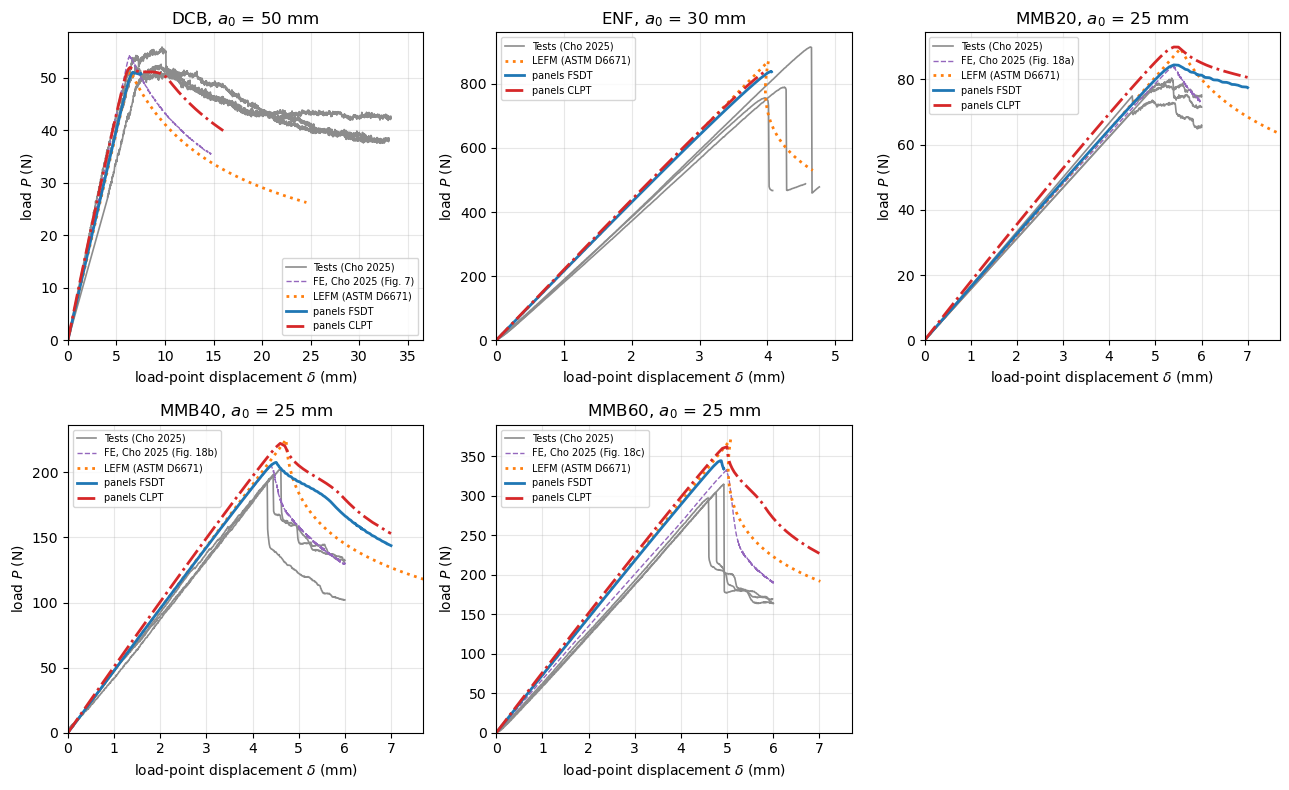

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (key, t) in zip(axes.flat, tests.items()):
    cs = {}
    for i, (d, P) in enumerate(curves[key]):
        cs['Tests (Cho 2025)' if i == 0 else '_test{0}'.format(i)] = (d, P, dict(color='0.55', lw=1.2))
    if key in fe:
        cs[fe[key][0]] = (fe_curves[key][0], fe_curves[key][1], dict(color='C4', lw=1, ls='--'))
    cs['LEFM (ASTM D6671)'] = (lefm[key][0], lefm[key][1], dict(color='C1', ls=':', lw=2))
    for model, col in (('fsdt', 'C0'), ('clpt', 'C3')):
        res = runs.get('{0}_{1}'.format(key, model))
        if res is not None:
            cs['panels ' + model.upper()] = (np.r_[0., res['delta']], np.r_[0., res['P']],
                                             dict(color=col, lw=2, ls='-' if model == 'fsdt' else '-.'))
    mu.plot_test(ax, cs, title='{0}, $a_0$ = {1:g} mm'.format(key, t['a0']))
    ax.set_xlim(0, 1.1*max(np.nanmax(c[0]) for k, c in cs.items() if not k.startswith('LEFM')))
    ax.legend(fontsize=7)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

In [10]:
info = ['| run | status | increments | size | run time (min) | machine |',
        '|---|---|---|---|---|---|']
for name, res in runs.items():
    info.append('| {0} | {1} | {2} | {3} | {4:.1f} | {5} |'.format(
        name, res['status'], len(res['delta']), res['size'], res['time']/60, res['machine']))
display(Markdown('\n'.join(info)))

| run | status | increments | size | run time (min) | panels | machine | study run |
|---|---|---|---|---|---|---|---|
| DCB_fsdt | stopped at delta = 7.526145434407929 | 93 | 7800 | 56.3 | 0.16.0 (ec104c0) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11; shared with other runs | DCB_a50_fsdt_case4_tri_K1e5_20261123_082210 |
| DCB_clpt | finished | 163 | 4680 | 30.3 | 0.16.0 (ec104c0) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11; shared with other runs | DCB_a50_clpt_case4_tri_20261123_073145 |
| ENF_fsdt | stopped at delta = 4.059167480468751 | 49 | 7400 | 18.8 | 0.16.0 (ec104c0) | Intel(R) Xeon(R) Gold 6130 CPU @ 2.10GHz, hpc12 node n12-144, 4 threads, Linux | ENF_a30_fsdt_case4_bil_20261123_150035 |
| ENF_clpt | stopped at delta = 3.9912231445312516 | 46 | 4272 | 15.7 | 0.16.0 (ec104c0) | Intel(R) Xeon(R) Gold 6130 CPU @ 2.10GHz, hpc12 node n12-141, 4 threads, Linux | ENF_a30_clpt_case4_bil_20261123_133324 |
| MMB20_fsdt | finished | 155 | 7400 | 56.5 | 0.16.0 (ec104c0) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11; shared with other runs | MMB20_a25_fsdt_case4_tri_K1e5_20261123_091832 |
| MMB20_clpt | finished | 70 | 4440 | 10.0 | 0.16.0 (ec104c0) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11; shared with other runs | MMB20_a25_clpt_case4_tri_20261123_080639 |
| MMB40_fsdt | finished | 433 | 7400 | 214.6 | 0.16.0 (ec104c0) | Intel(R) Xeon(R) Gold 6130 CPU @ 2.10GHz, hpc12 node n12-134, 4 threads, Linux | MMB40_a25_fsdt_case4_tri_K1e5_loadline_20261123_110200 |
| MMB40_clpt | finished | 70 | 4440 | 15.5 | 0.16.0 (ec104c0) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11; shared with other runs | MMB40_a25_clpt_case4_tri_20261123_080639 |
| MMB60_fsdt | stopped at delta = 4.927203739726018 | 93 | 7400 | 30.3 | 0.16.0 (ec104c0) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11; shared with other runs | MMB60_a25_fsdt_case4_tri_K1e5_20261123_095119 |
| MMB60_clpt | finished | 172 | 4440 | 61.7 | 0.16.0 (ec104c0) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11; shared with other runs | MMB60_a25_clpt_case4_tri_20261123_081639 |

## Discussion

- **Peaks against the tests.** With the identified thickness, the DCB peaks are 3.0% (CLPT) and 4.7% (FSDT) below the mean of the tests and the ENF peak is 2.3% above it. The MMB peaks are 5-13% above the tests with FSDT arms and 13-19% above them with CLPT arms. The CLPT peaks are within 2.5% of LEFM with the crack-tip toughness for the DCB and the MMB, and 3.7% below it for the ENF: the bridging law, which acts behind the crack-tip law, changes the peaks little (the bilinear law, run in the study, is within 1%).
- **Peaks against the FE analyses of Cho et al.** With FSDT arms the MMB peaks are within 0.2%, 1.0% and 3.4% of the FE analyses with the bridging law without shear strength, which are themselves 4-9% above the tests. The DCB FE with the initiation toughness is 1.2% above the tests.
- **Thickness.** The arm thickness is identified, not measured, and it decides the agreement with the tests: in the study, $h$ = 2.00 mm, the mean of the ENF and MMB records with simple beam theory, lowers the peaks by 5-7%.
- **Published toughnesses.** The mixed-mode toughnesses of Cho et al. (Table 7, p. 8), to which their exponent $\eta$ is fitted, are 12-26% above the toughness that ASTM D6671 gives from their own peak loads (Fig. 18) and measured compliances, independently of $h$; this accounts for part of the excess of the MMB peaks.
- **After the peak.** The bridging law of `panels`, driven by the opening and without shear stiffness, keeps the full mode I bridging toughness at every mode ratio. At $\delta$ = 6 mm it overpredicts the load of the MMB tests at 40 and 60% by 40-60%, more than the FE analyses of Cho et al., whose mixed-mode law scales the bridging branch through the Benzeggagh-Kenane criterion. In these tests the bridging fades as the mode II share grows, which a bridging law identified in mode I cannot know.
- **Robustness.** The FSDT DCB stops at $\delta$ = 7.53 mm and the FSDT MMB at 60% at $\delta$ = 4.93 mm, after the peak, when the increments are cut below the minimum (the curves are shown up to there); the FSDT MMB at 40% was run under control of the load-line separation for this reason. The ENF runs stop at the peak ($\delta$ = 3.99 mm CLPT, 4.06 mm FSDT), where the crack grows unstably. Load-line control is not defined for the DCB.
- **Lever weight.** Not published and not modelled. With ASTM D6671-22 Eqs. 17-18, levers of 8-9 N, as in other MMB rigs, would lower the measured critical loads by 0.5-2.7%.